# Research Question 2

## What is the relationship between track length and popularity?

**Null Hypothesis ($H_0$):** Track length has no effect on popularity (the true relationship is flat, EDF = 1).

**Alternative Hypothesis ($H_a$):** Track length has a statistically significant non-linear effect on popularity, deviating from a flat line (EDF > 1).

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from spotify_data_analytics import (
    DataFilterPipeline,
    DataLoader,
    ExpressionTransformRule,
    GamAnalyzer,
    MaxThresholdFilter,
    MinThresholdFilter,
    create_gam_fit,
)

%matplotlib inline

### Data Loading and Filtering

We load the data and apply the following filters:
* Transform duration_ms into duration_min by dividing by 60,000.
* Filter out tracks with duration_min less than 1.
* Filter out tracks with duration_min more than 10.
* Filter out tracks with popularity 0.

In [11]:
file_path = "../data/normalized/tracks.csv"
target_column = "popularity"
feature_column = "duration_ms"

data_loader = DataLoader(
    file_path=file_path,
    target=target_column,
    features=[feature_column],
)
raw_data = data_loader.load_and_clean()

pipeline = DataFilterPipeline()
pipeline.add_rule(
    ExpressionTransformRule(
        (pl.col(feature_column) / 60000.0).alias("duration_min")
    )
)
pipeline.add_rule(MinThresholdFilter(column="duration_min", threshold=1.0))
pipeline.add_rule(MaxThresholdFilter(column="duration_min", threshold=10.0))
pipeline.add_rule(MinThresholdFilter(column="popularity", threshold=1))

filtered_data = pipeline.apply(raw_data)

### Fitting the GAM and Printing the Summary

In [12]:
analyzer = GamAnalyzer(
    filtered_data,
    target=target_column,
    feature="duration_min",
)

x, y, x_grid, prediction, confidence_intervals, gam = (
    analyzer.fit_and_evaluate(
        n_splines=12,
        n_grid=200,
    )
)

print("=== GAM Statistical Summary ===")
gam.summary()

=== GAM Statistical Summary ===
LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     10.8656
Link Function:                     IdentityLink Log Likelihood:                               -528907.9615
Number of Samples:                        79096 AIC:                                          1057839.6542
                                                AICc:                                         1057839.6581
                                                GCV:                                              319.4674
                                                Scale:                                            319.3884
                                                Pseudo R-Squared:                                   0.0274
Featu

C:\Users\14257\AppData\Local\Temp\ipykernel_16104\1214008147.py:15: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


### Directional Testing and Inflection Point Calculation

This is not strictly necessary to answer the research question, though the results can be used for further analysis.

In [13]:
slopes = np.gradient(prediction, x_grid)

peak_index = np.argmax(prediction)
optimal_duration = x_grid[peak_index]

print(
    f"Optimal Song Duration (Peak Popularity): {optimal_duration:.2f} minutes"
)
print(f"Average Popularity at Peak: {prediction[peak_index]:.2f}")

help_zone_mask = x_grid < optimal_duration
hurt_zone_mask = x_grid >= optimal_duration

print(
    f"\nAverage slope in 'Help' zone (< {optimal_duration:.2f} min): {np.mean(slopes[help_zone_mask]):.4f}"
)
print(
    f"Average slope in 'Hurt' zone (>= {optimal_duration:.2f} min): {np.mean(slopes[hurt_zone_mask]):.4f}"
)

Optimal Song Duration (Peak Popularity): 3.35 minutes
Average Popularity at Peak: 39.75

Average slope in 'Help' zone (< 3.35 min): 5.7865
Average slope in 'Hurt' zone (>= 3.35 min): -0.9229


### Visualization

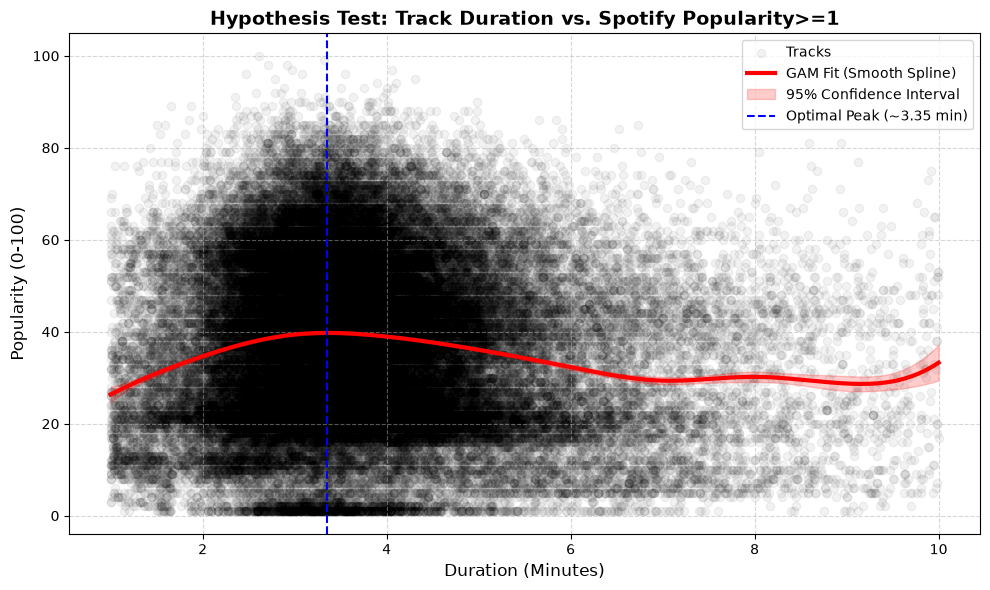

In [15]:
fig, ax = create_gam_fit(
    x,
    y,
    x_grid,
    prediction,
    confidence_intervals,
    title="Hypothesis Test: Track Duration vs. Spotify Popularity>=1",
)

ax.axvline(
    optimal_duration,
    color="blue",
    linestyle="--",
    label=f"Optimal Peak (~{optimal_duration:.2f} min)",
)
ax.legend(loc="upper right")

plt.show()